# Image Captioning - Part 3 - Transformers
## Authors: Erfan Ahmadi, Mohammad Ali Olama

# Part 1: Preparing Dataset

## Import libraries

In [1]:
!pip install scikit-image

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import os
import json
import re
from collections import Counter
import numpy as np
from PIL import Image
import random


import torch
from torch.utils.data import Dataset
import torchvision.transforms as transforms
import torch.nn as nn
import torchvision.models as models
import torch.nn.utils.rnn as rnn_utils
from torch.utils.data import DataLoader
from torchvision.models import EfficientNet_B0_Weights

from datasets import load_dataset, load_from_disk
from huggingface_hub import login

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from tqdm import tqdm # For progress bars
import pickle
import skimage.transform

import textwrap 
print("All libraries imported successfully.")

All libraries imported successfully.


In [58]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"

## Download Data and Display Samples

For the loading dataset part, I got strange errors at loading from Hugging face in this notebook. Hence, I had to download the dataset from somewhere else, upload it to my drive, and again download from drive to the local server. The commented code bellow is for downloading the dataset from Hugging face : 

In [3]:
# ds = load_dataset("jxie/flickr8k")  # -> dict with 'train', 'validation', 'test'
# print(ds)

In [4]:
# ds.save_to_disk("./flickr8k_dataset")

Load  the data from the Disk

In [5]:
ds = load_from_disk("./flickr8k_dataset")
print("Dataset loaded successfully.")

Dataset loaded successfully.



Dataset Structure:
DatasetDict({
    train: Dataset({
        features: ['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 6000
    })
    validation: Dataset({
        features: ['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 1000
    })
})

Exploring the 'train' split:
Displaying the 1th image from the training set with its 5 captions:


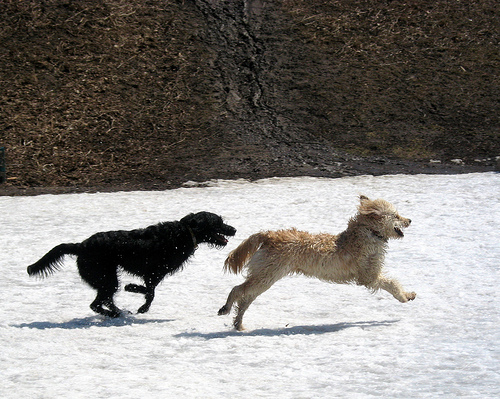

  - Caption 0: A black dog is running after a white dog in the snow .
  - Caption 1: Black dog chasing brown dog through snow
  - Caption 2: Two dogs chase each other across the snowy ground .
  - Caption 3: Two dogs play together in the snow .
  - Caption 4: Two dogs running through a low lying body of water .
Displaying the 2th image from the training set with its 5 captions:


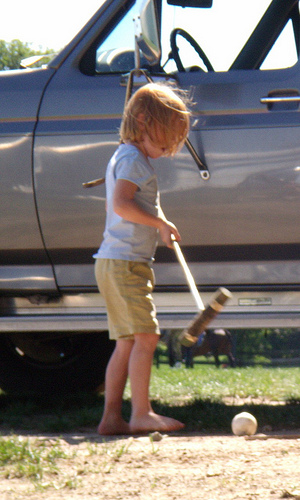

  - Caption 0: A little baby plays croquet .
  - Caption 1: A little girl plays croquet next to a truck .
  - Caption 2: The child is playing croquette by the truck .
  - Caption 3: The kid is in front of a car with a put and a ball .
  - Caption 4: The little boy is playing with a croquet hammer and ball beside the car .
Displaying the 3th image from the training set with its 5 captions:


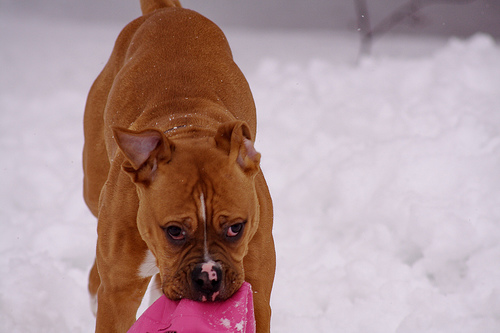

  - Caption 0: A brown dog in the snow has something hot pink in its mouth .
  - Caption 1: A brown dog in the snow holding a pink hat .
  - Caption 2: A brown dog is holding a pink shirt in the snow .
  - Caption 3: A dog is carrying something pink in its mouth while walking through the snow .
  - Caption 4: A dog with something pink in its mouth is looking forward .


In [6]:
print("\nDataset Structure:")
print(ds)

# --- Display a few Samples ---
print("\nExploring the 'train' split:")
train_data = ds['train']

for i in range (3):
    sample = train_data[i]
    print(f"Displaying the {i+1}th image from the training set with its 5 captions:")
    display(sample['image']) # In a Jupyter environment, this displays the image.

    for j in range(5):
        print(f"  - Caption {j}: {sample[f'caption_{j}']}")

In [7]:
# HYPER PARAMETERS

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 128

In [118]:
class FlickrDataset(Dataset):
    def __init__(self, hf_split, transform=None, seq_length=25):
        self.hf_split = hf_split
        self.transform = transform
        self.seq_length = seq_length

    def __len__(self):
        return len(self.hf_split) * 5

    def __getitem__(self, index):
        image_idx = index // 5
        caption_idx = index % 5
        data_point = self.hf_split[image_idx]

        image = data_point['image'].convert("RGB")
        caption = data_point[f'caption_{caption_idx}']

        if self.transform:
            image = self.transform(image)
            
        return image, caption
    
# Define the pipeline of image transformations
image_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    ),
])

seq_length = 25

val_dataset = FlickrDataset(ds['validation'], transform=image_transforms, seq_length=seq_length)
test_dataset = FlickrDataset(ds['test'], transform=image_transforms, seq_length=seq_length)


## Tokenizer Implementation

For the Transformer, we'll upgrade from our simple vocabulary to a more powerful, sub-word tokenizer. This is standard practice and handles rare words much more effectively. We'll use the Hugging Face tokenizers library.

Tasks Covered:

* Implement a modern tokenizer.

* Explain the importance of masking.

In [8]:
from tokenizers import Tokenizer
from tokenizers.models import WordPiece
from tokenizers.trainers import WordPieceTrainer
from tokenizers.pre_tokenizers import Whitespace

# --- Train a New Tokenizer ---
# First, ensure 'all_captions' list from the previous step is available
# Or recreate it if needed.
if 'all_captions' not in locals():
    all_captions = []
    for split in ds:
        for example in ds[split]:
            for i in range(5):
                all_captions.append(example[f'caption_{i}'])

# 1. Initialize a new Tokenizer
transformer_tokenizer = Tokenizer(WordPiece(unk_token="[UNK]"))
transformer_tokenizer.pre_tokenizer = Whitespace()

# 2. Train the tokenizer on our captions
trainer = WordPieceTrainer(special_tokens=["[UNK]", "[PAD]", "[SOS]", "[EOS]"])
transformer_tokenizer.train_from_iterator(all_captions, trainer)

# 3. Save the tokenizer
tokenizer_path = "transformer_tokenizer.json"
transformer_tokenizer.save(tokenizer_path)

# --- Load and Test ---
tokenizer = Tokenizer.from_file(tokenizer_path)
print(f"Tokenizer vocabulary size: {tokenizer.get_vocab_size()}")

# Example
encoded = tokenizer.encode("A dog is running on the grass")
print("Encoded IDs:", encoded.ids)
print("Decoded Tokens:", encoded.tokens)




Tokenizer vocabulary size: 13905
Encoded IDs: [28, 161, 162, 277, 155, 148, 272]
Decoded Tokens: ['A', 'dog', 'is', 'running', 'on', 'the', 'grass']


* **Why Masking is Important**: In the Transformer Decoder, **masking** is crucial during training to prevent the model from cheating. The model's task is to predict the next word in a sequence given the previous words.
    -   Without a mask, the self-attention mechanism would allow the model to "look ahead" at the future words in the caption it's supposed to be predicting.
    -   We use a **subsequent mask** (or causal mask) which is a square matrix that hides future tokens from the current position. This forces the model to make predictions based only on the past, simulating how it would generate text in a real-world scenario. This is the core principle behind auto-regressive models like GPT.

## Encoder and Positional Encoding

The Encoder is very similar to our first simple model, projecting the image into the Transformer's expected dimension. The new, critical component is Positional Encoding, which informs the Transformer about the order of words in a sequence.

In [29]:
import torch
import torch.nn as nn
import math

class EncoderCNN_Transformer(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        self.efficientnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        
        # Freeze all layers
        for param in self.efficientnet.parameters():
            param.requires_grad = False
            
        in_features = self.efficientnet.classifier[1].in_features
        # Replace the classifier with a projection layer to d_model
        self.efficientnet.classifier = nn.Linear(in_features, d_model)

    def forward(self, images):
        # The output is the image feature vector
        return self.efficientnet(images)

# The corrected PositionalEncoding class (batch_first compatible)

class PositionalEncoding(nn.Module):
    """
    Injects position information into the word embeddings.
    This version is compatible with batch_first=True.
    """
    def __init__(self, d_model, dropout=0.1, max_len=50):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        # Create the positional encoding matrix
        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        
        # --- FIX 1: The shape is now (1, max_len, d_model) for batch_first ---
        pe = torch.zeros(1, max_len, d_model)
        pe[0, :, 0::2] = torch.sin(position * div_term)
        pe[0, :, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe)

    def forward(self, x):
        """
        Args:
            x: Tensor of shape (batch_size, seq_len, d_model)
        """
        # --- FIX 2: Add pe to the input tensor ---
        # self.pe is (1, max_len, d_model). We slice it to the input's seq_len.
        # It will be broadcasted across the batch dimension.
        x = x + self.pe[:, :x.size(1)]
        return self.dropout(x)

* **Role of Positional Encoding**: Unlike an RNN which processes words one by one in order, a Transformer processes the entire sequence at once. It has no inherent sense of word order. **Positional Encoding** injects information about the position of each word into its embedding. It creates a unique "positional signature" for each step in the sequence using a clever combination of sine and cosine functions. By adding this signature to the word embedding, the model can learn to differentiate between "a dog chases a cat" and "a cat chases a dog."

## The Transformer Decoder Model

Here, we combine the embeddings, positional encoding, and the core nn.TransformerDecoder layer into a complete captioning model.

In [38]:
# The corrected Transformer model class

class DecoderOnly_Transformer(nn.Module):
    """The Transformer Decoder model that takes pre-computed features."""
    def __init__(self, d_model, nhead, num_decoder_layers, dim_feedforward, vocab_size):
        super().__init__()
        self.d_model = d_model
        
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        
        decoder_layer = nn.TransformerDecoderLayer(d_model, nhead, dim_feedforward, batch_first=True)
        self.transformer_decoder = nn.TransformerDecoder(decoder_layer, num_decoder_layers)
        
        self.fc_out = nn.Linear(d_model, vocab_size)
        self.pad_idx = tokenizer.token_to_id("[PAD]")
        
    def generate_square_subsequent_mask(self, sz):
        return torch.triu(torch.full((sz, sz), float('-inf')), diagonal=1)

    def forward(self, features, captions):
        memory = features.unsqueeze(1)
        tgt = captions[:, :-1]
        
        tgt_seq_len = tgt.shape[1]
        tgt_mask = self.generate_square_subsequent_mask(tgt_seq_len).to(features.device)
        tgt_padding_mask = (tgt == self.pad_idx)

        tgt_emb = self.pos_encoder(self.embedding(tgt) * math.sqrt(self.d_model))
        
        # --- THE FIX: Rename 'tgt_padding_mask' to 'tgt_key_padding_mask' ---
        output = self.transformer_decoder(
            tgt=tgt_emb, 
            memory=memory, 
            tgt_mask=tgt_mask, 
            tgt_key_padding_mask=tgt_padding_mask # This line is corrected
        )
        
        return self.fc_out(output)

    def generate_caption(self, features, max_len=30, device='cuda'):
        # This inference method remains the same and is correct.
        self.eval()
        memory = features.unsqueeze(0).unsqueeze(1)
        
        sos_idx = tokenizer.token_to_id("[SOS]")
        eos_idx = tokenizer.token_to_id("[EOS]")
        
        generated_ids = torch.tensor([[sos_idx]], device=device)
        
        for _ in range(max_len - 1):
            tgt_emb = self.pos_encoder(self.embedding(generated_ids) * math.sqrt(self.d_model))
            tgt_mask = self.generate_square_subsequent_mask(generated_ids.size(1)).to(device)
            
            # The inference call to the decoder does not use a padding mask, so it was unaffected.
            output = self.transformer_decoder(tgt_emb, memory, tgt_mask=tgt_mask)
            
            last_word_logits = self.fc_out(output[:, -1, :])
            predicted_id = torch.argmax(last_word_logits, dim=-1).unsqueeze(1)
            generated_ids = torch.cat([generated_ids, predicted_id], dim=1)
            
            if predicted_id.item() == eos_idx:
                break
                
        self.train()
        return tokenizer.decode(generated_ids.squeeze(0).tolist(), skip_special_tokens=True)

In [57]:
def save_checkpoint(state, filename="image_captioning_checkpoint.pth.tar"):
    """Saves the model's state to a file."""
    print("=> Saving checkpoint")
    torch.save(state, filename)

In [39]:
# File: precompute_features_transformer.py
import os
import torch
from tqdm import tqdm
import torchvision.models as models
import torch.nn as nn
import torchvision.transforms as transforms

# --- Ensure all necessary variables and classes are defined ---
# Make sure your Hugging Face dataset 'ds' is loaded.
# And your 'device' is set (e.g., to 'cuda').

# Hyperparameters for the Transformer's Encoder
d_model = 512 # This must match the d_model of your Transformer Decoder

# Image transformations must be consistent with what the model expects
image_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    ),
])


In [40]:


# 1. Initialize the Encoder
encoder = EncoderCNN_Transformer(d_model).to(device)
encoder.eval()

# 2. Add a unique integer ID to each image row (if not already done)
if 'image_id' not in ds['train'].features:
    print("Adding 'image_id' column to dataset splits...")
    ds['train'] = ds['train'].add_column("image_id", range(len(ds['train'])))
    ds['validation'] = ds['validation'].add_column("image_id", range(len(ds['validation'])))
    ds['test'] = ds['test'].add_column("image_id", range(len(ds['test'])))
else:
    print("'image_id' column already exists.")


'image_id' column already exists.


In [ ]:

# 3. Define the pre-computation function
def precompute_transformer_features(dataset_split, split_name):
    """
    Computes features for a dataset split and saves them as a dictionary.
    """
    print(f"\n--- Pre-computing Transformer features for {split_name} split ---")
    features_dict = {}
    with torch.no_grad():
        for item in tqdm(dataset_split):
            img_id = item['image_id']
            
            # Apply transforms, add batch dimension, and move to device
            image_tensor = image_transforms(item['image']).unsqueeze(0).to(device)
            
            # Get the feature vector from the encoder
            feature = encoder(image_tensor).squeeze(0).cpu()
            
            # Store it in the dictionary with the unique ID as the key
            features_dict[img_id] = feature
            
    output_path = f"transformer_{split_name}_features.pt"
    torch.save(features_dict, output_path)
    print(f"Saved {len(features_dict)} features to '{output_path}'.")

# 4. Run the pre-computation for all splits
precompute_transformer_features(ds['train'], "train")
precompute_transformer_features(ds['validation'], "validation")
precompute_transformer_features(ds['test'], "test")

print("\nAll Transformer features have been pre-computed and saved. ✅")

Adding 'image_id' column to dataset splits...

--- Pre-computing Transformer features for train split ---


100%|██████████| 6000/6000 [01:43<00:00, 57.89it/s]


Saved 6000 features to 'transformer_train_features.pt'.

--- Pre-computing Transformer features for validation split ---


100%|██████████| 1000/1000 [00:17<00:00, 58.79it/s]


Saved 1000 features to 'transformer_validation_features.pt'.

--- Pre-computing Transformer features for test split ---


100%|██████████| 1000/1000 [00:18<00:00, 55.10it/s]

Saved 1000 features to 'transformer_test_features.pt'.

All Transformer features have been pre-computed and saved. ✅


In [90]:
# File: your_main_script.py
class FlickrDataset_Transformer(Dataset):
    def __init__(self, hf_split, tokenizer, feature_file, seq_length=30):
        self.hf_split = hf_split
        self.tokenizer = tokenizer
        self.seq_length = seq_length
        self.features_dict = torch.load(feature_file)
        
        self.samples = []
        for item in self.hf_split:
            img_id = item['image_id']
            for i in range(5):
                self.samples.append((img_id, item[f'caption_{i}']))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        img_id, caption = self.samples[index]
        features = self.features_dict[img_id]
        
        tokenized = self.tokenizer.encode(caption)
        caption_vec = [self.tokenizer.token_to_id("[SOS]")] + tokenized.ids + [self.tokenizer.token_to_id("[EOS]")]
        
        pad_id = self.tokenizer.token_to_id("[PAD]")
        if len(caption_vec) < self.seq_length:
            caption_vec += [pad_id] * (self.seq_length - len(caption_vec))
        else:
            caption_vec = caption_vec[:self.seq_length-1] + [self.tokenizer.token_to_id("[EOS]")]
            
        return features, torch.tensor(caption_vec)

# --- Create DataLoaders ---
train_dataset_tf = FlickrDataset_Transformer(ds['train'], tokenizer, "transformer_train_features.pt")
val_dataset_tf = FlickrDataset_Transformer(ds['validation'], tokenizer, "transformer_validation_features.pt")
test_dataset_tf = FlickrDataset_Transformer(ds['test'], tokenizer, "transformer_test_features.pt")

# # Use the same collate_fn and create your DataLoaders
train_loader_precomp = DataLoader(train_dataset_tf, batch_size=batch_size, shuffle=True,  num_workers=4, pin_memory=True)
val_loader_precomp = DataLoader(val_dataset_tf, batch_size=batch_size, shuffle=False,  num_workers=4, pin_memory=True)
test_loader_precomp = DataLoader(test_dataset_tf, batch_size=batch_size, shuffle=False,  num_workers=4, pin_memory=True)

# ... (create val_loader_tf and test_loader_tf)

The same dataset but modified based on transformer model

Now we set hyperparameters

In [91]:
# -- Model, Loss, Optimizer --
d_model = 512
nhead = 8
num_decoder_layers = 4
dim_feedforward = 2048
vocab_size = tokenizer.get_vocab_size()
num_epochs = 20

model_tf = DecoderOnly_Transformer(d_model, nhead, num_decoder_layers, dim_feedforward, vocab_size).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=tokenizer.token_to_id("[PAD]"))
optimizer = torch.optim.Adam(model_tf.parameters(), lr=1e-4)

The visualization part is also similar to previous functions

In [107]:
# The updated display function for the pre-computed Transformer model

# --- Function to reverse the normalization for display ---
def denormalize_image(tensor, mean, std):
    """Reverses the normalization on an image tensor."""
    tensor = tensor.clone() # Clone to avoid modifying the original tensor
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m) # tensor = tensor * std + mean
    return tensor



# Get the mean and std used for normalization
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

# Use a more visually appealing style for the plot
plt.style.use('seaborn-v0_8-whitegrid')


def show_example_prediction_by_id(model, feature_dataset, image_dataset, device , idx):
    """
    Selects a random sample, generates a caption using the Transformer model,
    and displays the original image with the result.
    
    Args:
        model: The trained DecoderOnly_Transformer model.
        feature_dataset: The dataset that loads pre-computed features (e.g., test_dataset_tf).
        original_hf_split: The original Hugging Face dataset split (e.g., ds['test']).
        device: The device ('cuda' or 'cpu').
    """
    model.eval()
    
    # 2. Get the pre-computed features for the model
    features, _= feature_dataset[idx]
    features = features.to(device)
    
    # 3. Get the original image for display using the unique ID
    # Get the unique image ID from our dataset's sample mapping
    original_image, _= image_dataset[idx]
    
    # 4. Generate the caption using the Transformer's method
    # Note: We no longer need to pass the vocab/tokenizer object
    generated_caption = model.generate_caption(features, device=device)
    print(generated_caption)
    
    # 5. Display the original image with the generated caption
    print("\n--- Example Prediction (Transformer Model) ---")
    denormalized_img = denormalize_image(original_image.cpu(), mean, std).permute(1, 2, 0)
    plt.imshow(denormalized_img)
    plt.title(f"Generated: {textwrap.fill(generated_caption, 40)}")
    plt.axis('off')
    plt.show()
    
    model.train()
    return generated_caption

def show_example_prediction_transformer(model, feature_dataset, image_dataset, device):
    """
    Selects a random sample, generates a caption using the Transformer model,
    and displays the original image with the result.
    
    Args:
        model: The trained DecoderOnly_Transformer model.
        feature_dataset: The dataset that loads pre-computed features (e.g., test_dataset_tf).
        original_hf_split: The original Hugging Face dataset split (e.g., ds['test']).
        device: The device ('cuda' or 'cpu').
    """
    
    # 1. Select a random sample index from your pre-computed dataset
    idx = random.randint(0, len(feature_dataset) - 1)
    return show_example_prediction_by_id(model, feature_dataset, image_dataset, device , idx)

Now we define the training procedure with 50 epochs as the previous models. 
(These epochs were sufficient for training a good transformer model as we observed)

In [93]:
def train_transformer_model(model, train_loader, val_loader, optimizer, criterion, device, num_epochs, image_val_dataset):
    """The main training and validation loop for the attention model."""
    
    train_losses = []
    val_losses = []

    for epoch in range(num_epochs):
        # --- Training Phase ---
        model.train()
        epoch_train_loss = 0.0
        train_iterator = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        
        for features, captions in train_iterator:
            features = features.to(device)
            captions = captions.to(device)
            
            optimizer.zero_grad()
            outputs = model(features, captions)
            
            targets = captions[:, 1:].reshape(-1)
            outputs = outputs.reshape(-1, vocab_size)
            
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()
            
            
            
            
        avg_train_loss = epoch_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        # -- Validation Loop --
        model_tf.eval()
        epoch_val_loss = 0
        with torch.no_grad():
            for features, captions in tqdm(val_loader, desc=f"Epoch {epoch+1} [Val]"):
                features, captions = features.to(device), captions.to(device)
                outputs = model_tf(features, captions)
                targets = captions[:, 1:].reshape(-1)
                outputs = outputs.reshape(-1, vocab_size)
                loss = criterion(outputs, targets)
                epoch_val_loss += loss.item()
        
        avg_val_loss = epoch_val_loss / len(val_loader)
        val_losses.append(avg_val_loss)
        
        
        # --- End of Epoch ---
        print(f"\nEpoch {epoch+1}/{num_epochs} -> Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}")
        
        # Save checkpoint
        checkpoint = {'epoch': epoch + 1, 'state_dict': model.state_dict(), 'optimizer': optimizer.state_dict()}
        save_checkpoint(checkpoint, filename=f"transformer_checkpoint.pth.tar")

        # --- UPDATE THIS LINE ---
        # Call the new function, passing the original image dataset
        show_example_prediction_transformer(model, val_loader.dataset, image_val_dataset, device)
    return train_losses, val_losses

Epoch 1/50 [Train]:   0%|          | 0/235 [00:00<?, ?it/s]/home/ma_olama/.conda/envs/llm_proj/lib/python3.12/site-packages/torch/nn/functional.py:6041: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(
Epoch 1 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.13it/s]



Epoch 1/50 -> Train Loss: 4.6925, Val Loss: 3.7988
=> Saving checkpoint
A man in a blue shirt is jumping over a red shirt is jumping over a snowy water .

--- Example Prediction (Transformer Model) ---


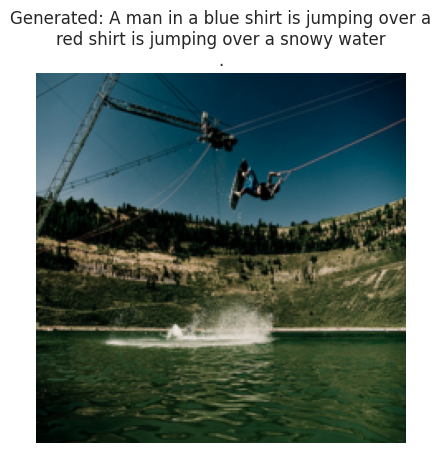

Epoch 2 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.39it/s]



Epoch 2/50 -> Train Loss: 3.5220, Val Loss: 3.4038
=> Saving checkpoint
A brown dog is running through the grass .

--- Example Prediction (Transformer Model) ---


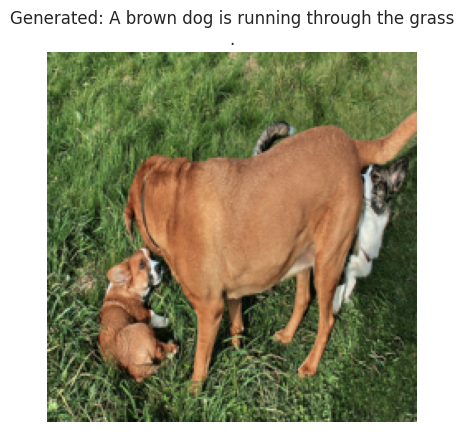

Epoch 3 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.87it/s]



Epoch 3/50 -> Train Loss: 3.1869, Val Loss: 3.2155
=> Saving checkpoint
A young girl in a blue shirt is jumping on a blue and white dog .

--- Example Prediction (Transformer Model) ---


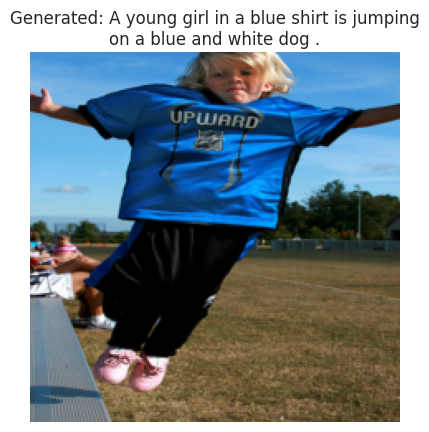

Epoch 4 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.86it/s]



Epoch 4/50 -> Train Loss: 2.9741, Val Loss: 3.0924
=> Saving checkpoint
A woman in a red shirt is sitting on a sidewalk .

--- Example Prediction (Transformer Model) ---


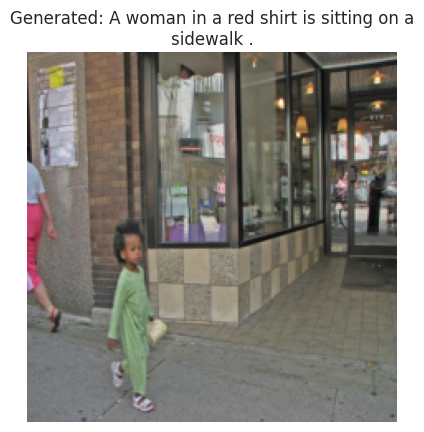

Epoch 5 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.25it/s]



Epoch 5/50 -> Train Loss: 2.8195, Val Loss: 3.0211
=> Saving checkpoint
A girl in a pink shirt is jumping into a pool .

--- Example Prediction (Transformer Model) ---


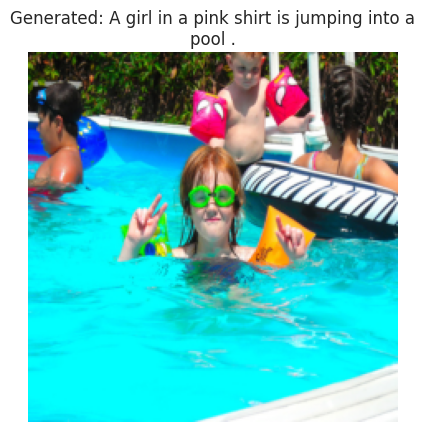

Epoch 6 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.73it/s]



Epoch 6/50 -> Train Loss: 2.6926, Val Loss: 2.9625
=> Saving checkpoint
A boy in a blue shirt and blue jeans is playing with a red and blue shirt .

--- Example Prediction (Transformer Model) ---


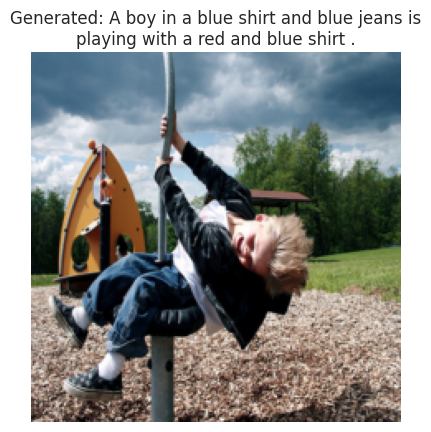

Epoch 7 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.26it/s]



Epoch 7/50 -> Train Loss: 2.5855, Val Loss: 2.9176
=> Saving checkpoint
A man and a woman are sitting at a table .

--- Example Prediction (Transformer Model) ---


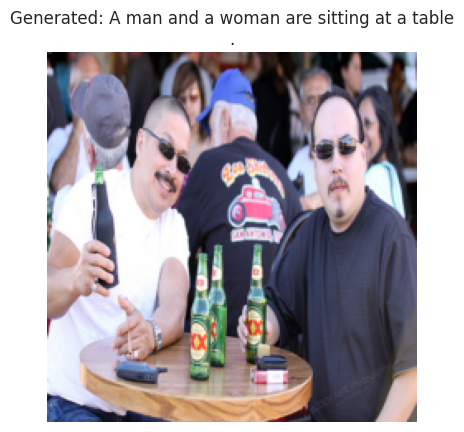

Epoch 8 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.24it/s]



Epoch 8/50 -> Train Loss: 2.4901, Val Loss: 2.8895
=> Saving checkpoint
A black and white dog is running through a field of grass .

--- Example Prediction (Transformer Model) ---


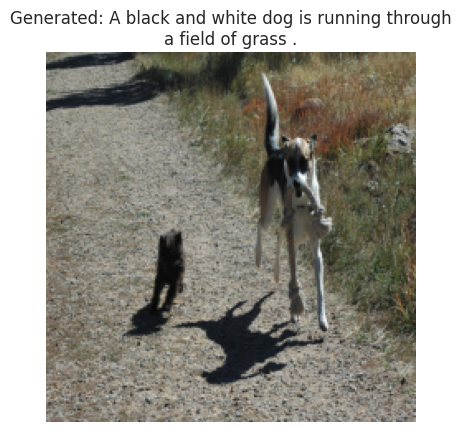

Epoch 9 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.70it/s]



Epoch 9/50 -> Train Loss: 2.4006, Val Loss: 2.8706
=> Saving checkpoint
A basketball player in a red jersey is being blocked by another player in blue .

--- Example Prediction (Transformer Model) ---


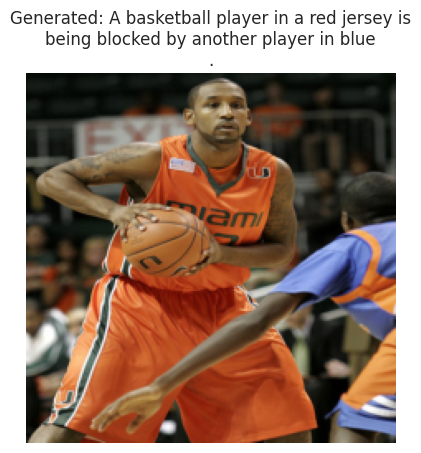

Epoch 10 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.44it/s]



Epoch 10/50 -> Train Loss: 2.3203, Val Loss: 2.8494
=> Saving checkpoint
A group of people are riding on a skateboard .

--- Example Prediction (Transformer Model) ---


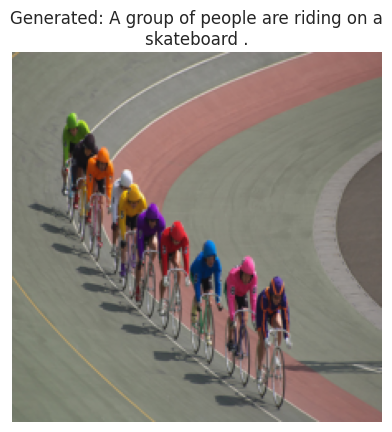

Epoch 11 [Val]: 100%|██████████| 40/40 [00:01<00:00, 32.77it/s]



Epoch 11/50 -> Train Loss: 2.2425, Val Loss: 2.8489
=> Saving checkpoint
A dog is jumping over a hurdle .

--- Example Prediction (Transformer Model) ---


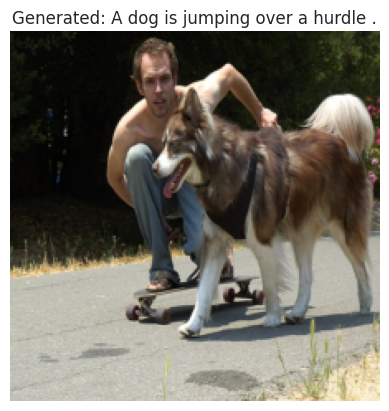

Epoch 12 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.20it/s]



Epoch 12/50 -> Train Loss: 2.1685, Val Loss: 2.8398
=> Saving checkpoint
A man is standing next to a sign that says " sign .

--- Example Prediction (Transformer Model) ---


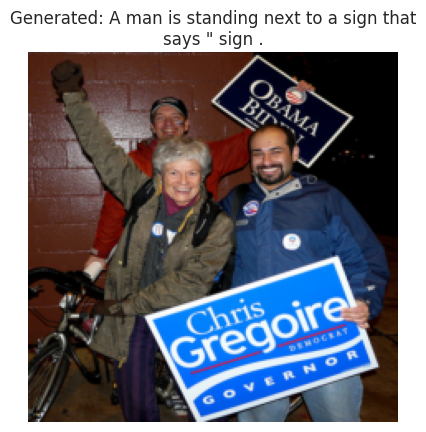

Epoch 13 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.83it/s]



Epoch 13/50 -> Train Loss: 2.1019, Val Loss: 2.8375
=> Saving checkpoint
A man and a woman are walking along a bridge .

--- Example Prediction (Transformer Model) ---


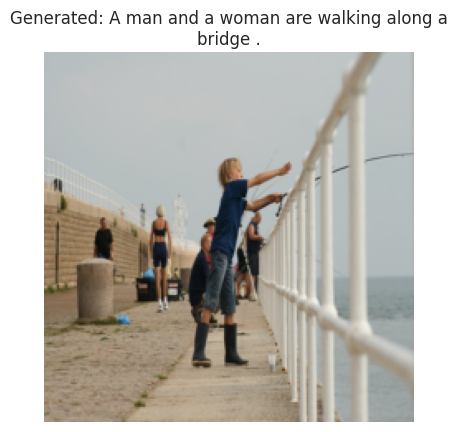

Epoch 14 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.24it/s]



Epoch 14/50 -> Train Loss: 2.0321, Val Loss: 2.8409
=> Saving checkpoint
A dog with a red collar is standing in the water .

--- Example Prediction (Transformer Model) ---


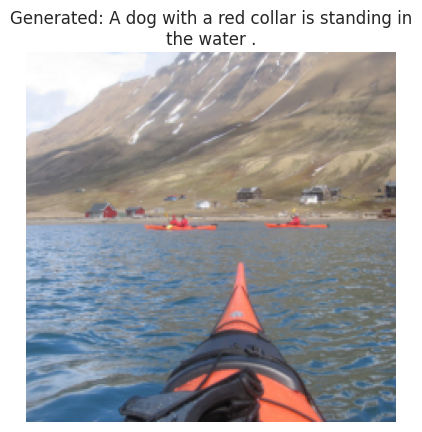

Epoch 15 [Val]: 100%|██████████| 40/40 [00:01<00:00, 32.81it/s]



Epoch 15/50 -> Train Loss: 1.9668, Val Loss: 2.8518
=> Saving checkpoint
A man in a black shirt is skateboarding on a city street .

--- Example Prediction (Transformer Model) ---


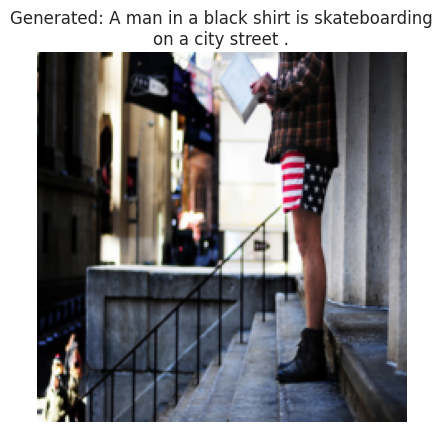

Epoch 16 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.01it/s]



Epoch 16/50 -> Train Loss: 1.9028, Val Loss: 2.8581
=> Saving checkpoint
A man in a black shirt and jeans stands in front of a white building .

--- Example Prediction (Transformer Model) ---


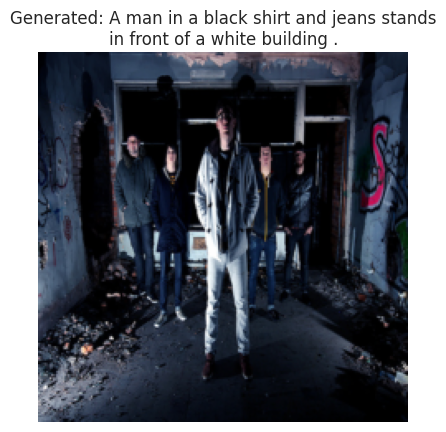

Epoch 17 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.14it/s]



Epoch 17/50 -> Train Loss: 1.8415, Val Loss: 2.8683
=> Saving checkpoint
A man in a white shirt and a woman in a black dress holding a newspaper .

--- Example Prediction (Transformer Model) ---


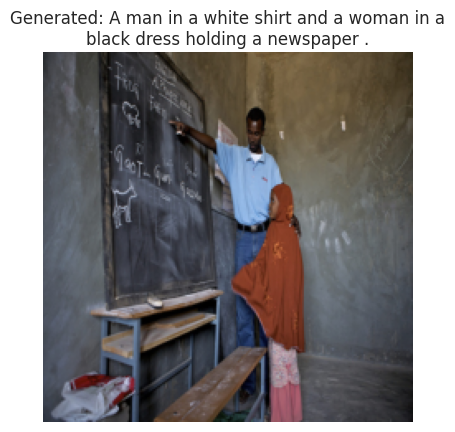

Epoch 18 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.54it/s]



Epoch 18/50 -> Train Loss: 1.7820, Val Loss: 2.8813
=> Saving checkpoint
A young boy is jumping on a red swing .

--- Example Prediction (Transformer Model) ---


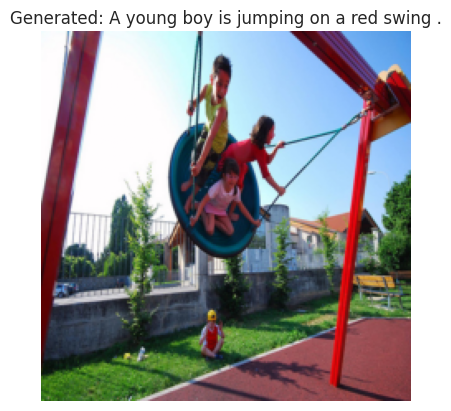

Epoch 19 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.90it/s]



Epoch 19/50 -> Train Loss: 1.7244, Val Loss: 2.8996
=> Saving checkpoint
A brown dog is jumping over a low cut - colored dog .

--- Example Prediction (Transformer Model) ---


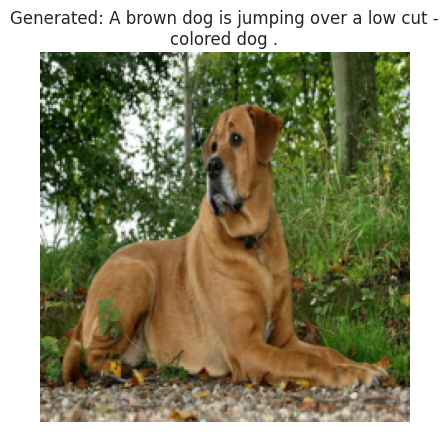

Epoch 20 [Val]: 100%|██████████| 40/40 [00:01<00:00, 35.53it/s]



Epoch 20/50 -> Train Loss: 1.6678, Val Loss: 2.9188
=> Saving checkpoint
A child in a blue jacket and jacket is skiing .

--- Example Prediction (Transformer Model) ---


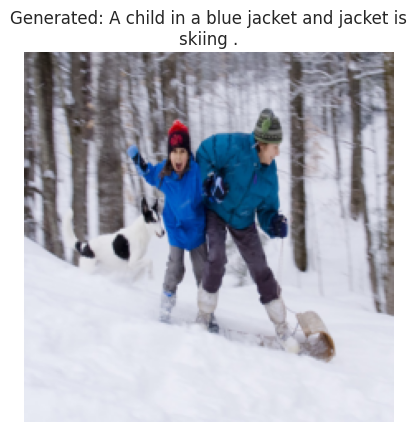

Epoch 21 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.37it/s]



Epoch 21/50 -> Train Loss: 1.6129, Val Loss: 2.9369
=> Saving checkpoint
A little girl in a pink dress is walking down the sidewalk .

--- Example Prediction (Transformer Model) ---


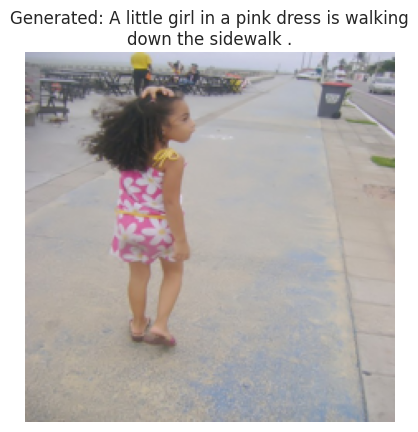

Epoch 22 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.91it/s]



Epoch 22/50 -> Train Loss: 1.5590, Val Loss: 2.9578
=> Saving checkpoint
A man and a woman are sitting on a bench .

--- Example Prediction (Transformer Model) ---


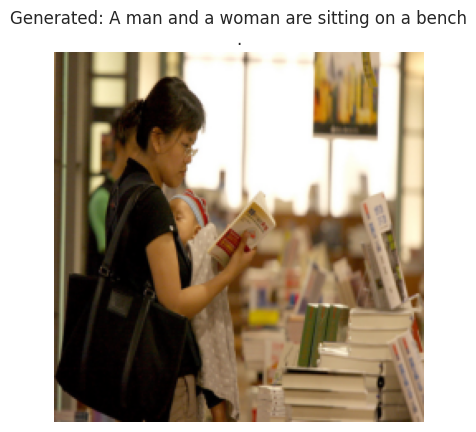

Epoch 23 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.89it/s]



Epoch 23/50 -> Train Loss: 1.5094, Val Loss: 2.9761
=> Saving checkpoint
A man in a black shirt is standing next to a woman in a blue shirt .

--- Example Prediction (Transformer Model) ---


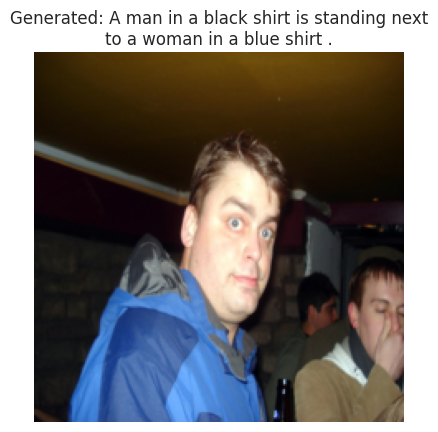

Epoch 24 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.62it/s]



Epoch 24/50 -> Train Loss: 1.4596, Val Loss: 3.0030
=> Saving checkpoint
A person is standing in the water with a red helmet .

--- Example Prediction (Transformer Model) ---


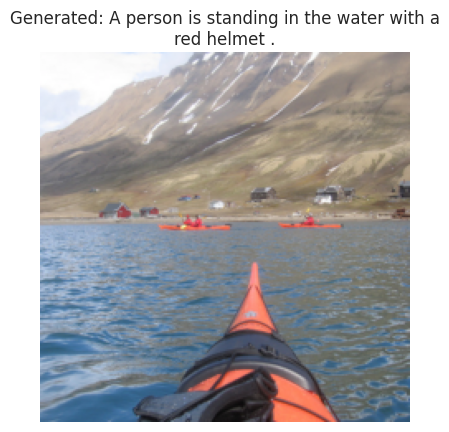

Epoch 25 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.51it/s]



Epoch 25/50 -> Train Loss: 1.4095, Val Loss: 3.0355
=> Saving checkpoint
A skateboarder jumps off a rail .

--- Example Prediction (Transformer Model) ---


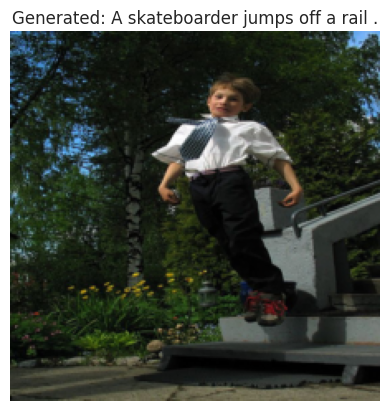

Epoch 26 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.76it/s]



Epoch 26/50 -> Train Loss: 1.3636, Val Loss: 3.0521
=> Saving checkpoint
A woman in a pink shirt sits on a stone bench with her back to a man in a yellow jacket .

--- Example Prediction (Transformer Model) ---


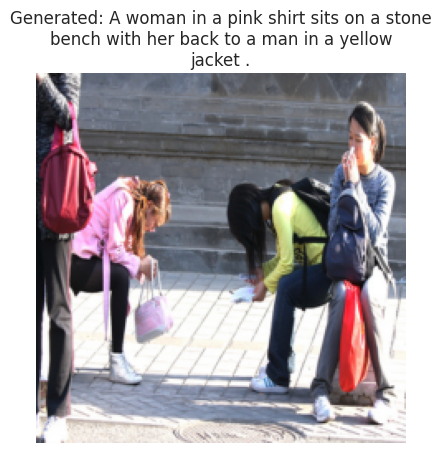

Epoch 27 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.30it/s]



Epoch 27/50 -> Train Loss: 1.3189, Val Loss: 3.0885
=> Saving checkpoint
A woman wearing a yellow hat and sunglasses smiles .

--- Example Prediction (Transformer Model) ---


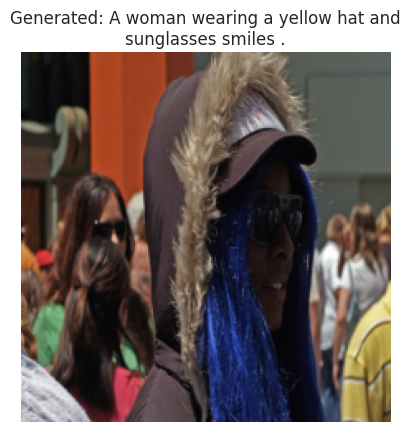

Epoch 28 [Val]: 100%|██████████| 40/40 [00:01<00:00, 32.26it/s]



Epoch 28/50 -> Train Loss: 1.2743, Val Loss: 3.1188
=> Saving checkpoint
A German shepherd jumps off a wooden porch .

--- Example Prediction (Transformer Model) ---


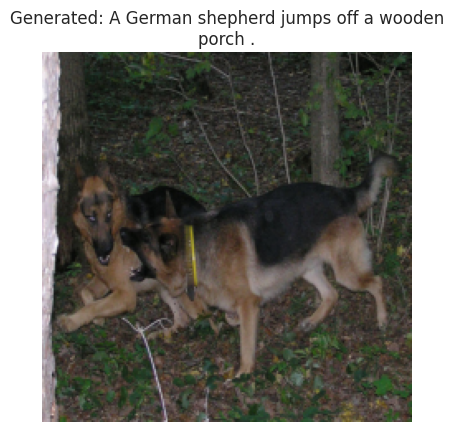

Epoch 29 [Val]: 100%|██████████| 40/40 [00:01<00:00, 32.96it/s]



Epoch 29/50 -> Train Loss: 1.2333, Val Loss: 3.1454
=> Saving checkpoint
A brown dog is running away from a black dog .

--- Example Prediction (Transformer Model) ---


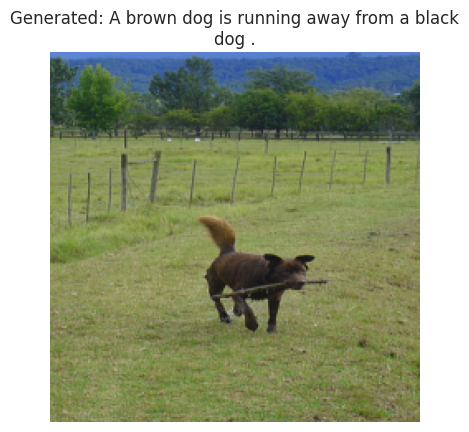

Epoch 30 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.01it/s]



Epoch 30/50 -> Train Loss: 1.1946, Val Loss: 3.1768
=> Saving checkpoint
A child in a red shirt is on a playground .

--- Example Prediction (Transformer Model) ---


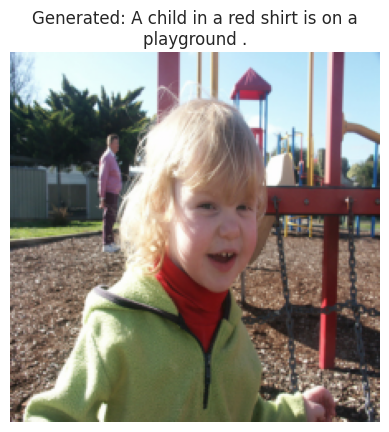

Epoch 31 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.87it/s]



Epoch 31/50 -> Train Loss: 1.1534, Val Loss: 3.2168
=> Saving checkpoint
Two women in red dresses hold a drink while a man watches .

--- Example Prediction (Transformer Model) ---


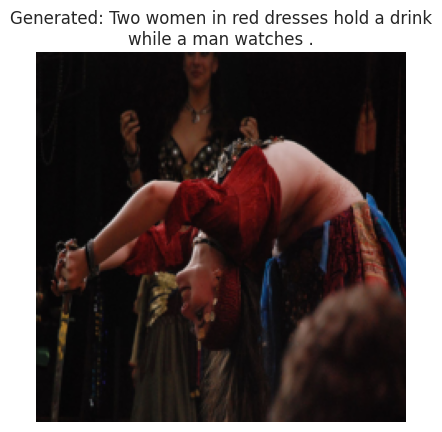

Epoch 32 [Val]: 100%|██████████| 40/40 [00:01<00:00, 32.34it/s]



Epoch 32/50 -> Train Loss: 1.1164, Val Loss: 3.2392
=> Saving checkpoint
Two men in racing suits are running in a parking lot .

--- Example Prediction (Transformer Model) ---


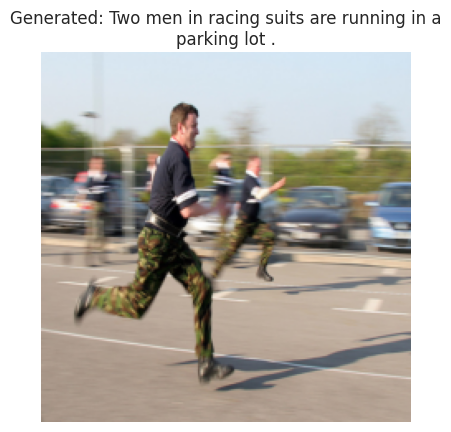

Epoch 33 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.21it/s]



Epoch 33/50 -> Train Loss: 1.0785, Val Loss: 3.2739
=> Saving checkpoint
A black dog walks along a stream .

--- Example Prediction (Transformer Model) ---


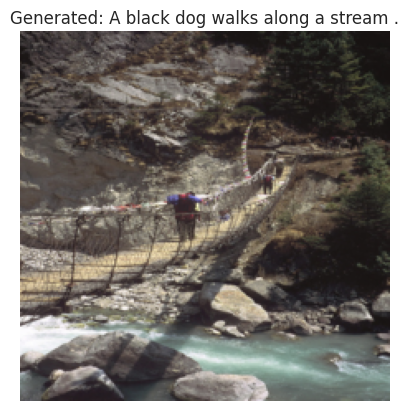

Epoch 34 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.69it/s]



Epoch 34/50 -> Train Loss: 1.0452, Val Loss: 3.2970
=> Saving checkpoint
A young boy in swim trunks is playing in the sand at the beach .

--- Example Prediction (Transformer Model) ---


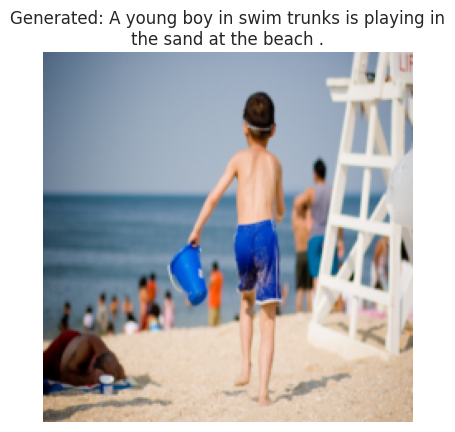

Epoch 35 [Val]: 100%|██████████| 40/40 [00:01<00:00, 32.75it/s]



Epoch 35/50 -> Train Loss: 1.0100, Val Loss: 3.3326
=> Saving checkpoint
A hockey goalie lays on the ice and team in front of the goal .

--- Example Prediction (Transformer Model) ---


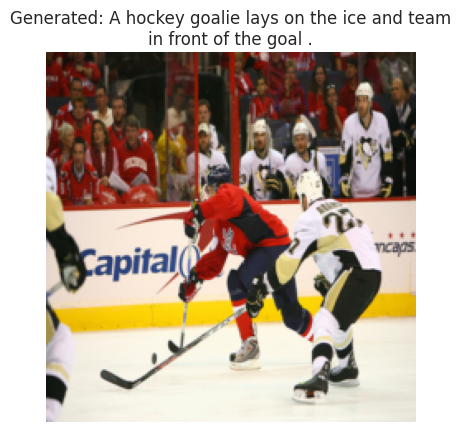

Epoch 36 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.32it/s]



Epoch 36/50 -> Train Loss: 0.9792, Val Loss: 3.3750
=> Saving checkpoint
A blue and white car is inside a turn .

--- Example Prediction (Transformer Model) ---


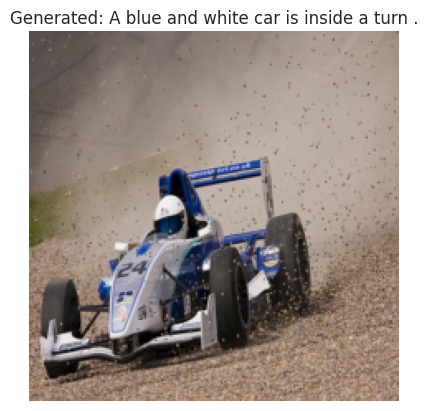

Epoch 37 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.31it/s]



Epoch 37/50 -> Train Loss: 0.9486, Val Loss: 3.4094
=> Saving checkpoint
Two people are walking in the snow with a dog in the background .

--- Example Prediction (Transformer Model) ---


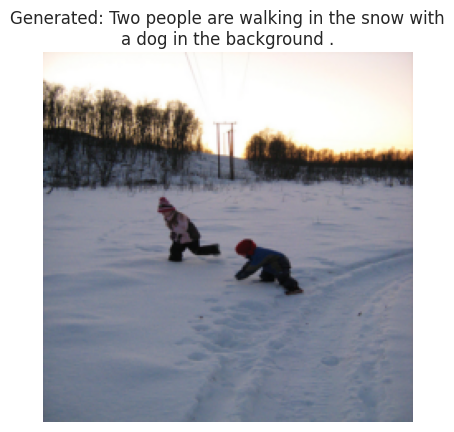

Epoch 38 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.68it/s]



Epoch 38/50 -> Train Loss: 0.9183, Val Loss: 3.4435
=> Saving checkpoint
A woman is sitting on a chair and holding a cup .

--- Example Prediction (Transformer Model) ---


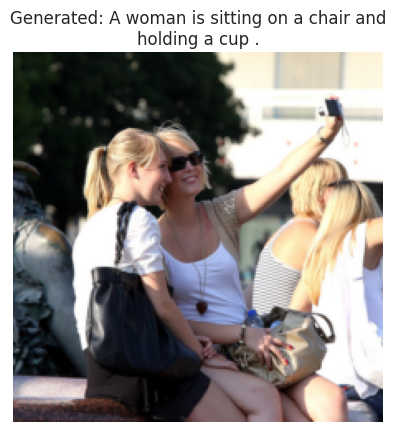

Epoch 39 [Val]: 100%|██████████| 40/40 [00:01<00:00, 35.54it/s]



Epoch 39/50 -> Train Loss: 0.8878, Val Loss: 3.4790
=> Saving checkpoint
A black dog jumps in the snow .

--- Example Prediction (Transformer Model) ---


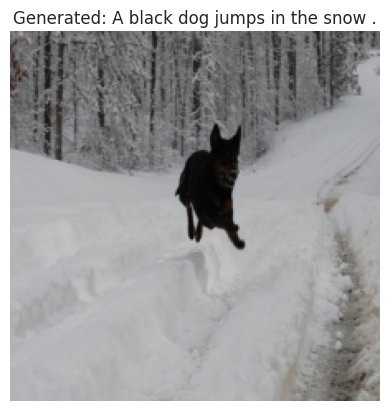

Epoch 40 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.93it/s]



Epoch 40/50 -> Train Loss: 0.8618, Val Loss: 3.5176
=> Saving checkpoint
A dog is running through the grass with a stick in its mouth .

--- Example Prediction (Transformer Model) ---


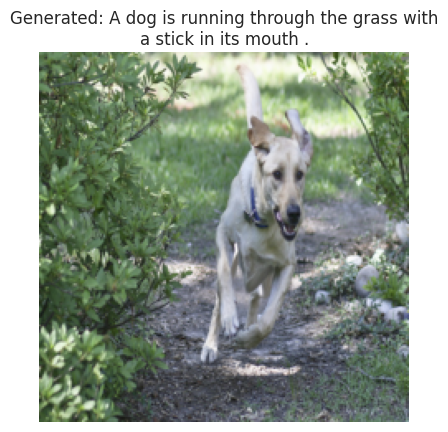

Epoch 41 [Val]: 100%|██████████| 40/40 [00:01<00:00, 35.36it/s]



Epoch 41/50 -> Train Loss: 0.8368, Val Loss: 3.5493
=> Saving checkpoint
A football player is running with the ball as a crowd of people watch .

--- Example Prediction (Transformer Model) ---


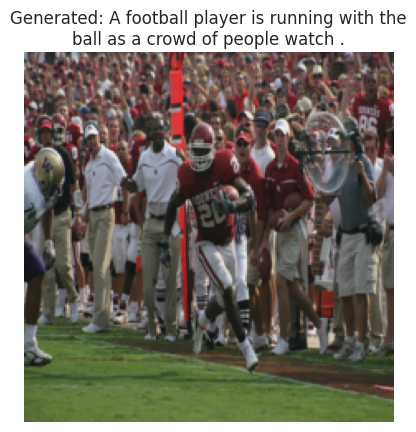

Epoch 42 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.17it/s]



Epoch 42/50 -> Train Loss: 0.8105, Val Loss: 3.5795
=> Saving checkpoint
A child is jumping on a red swing set .

--- Example Prediction (Transformer Model) ---


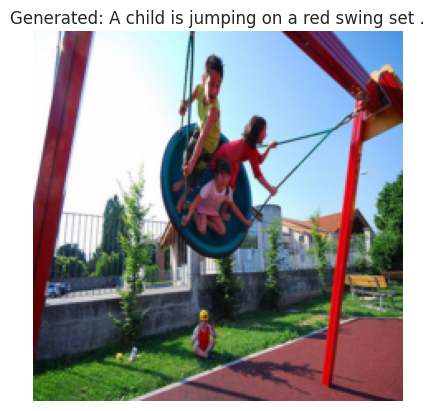

Epoch 43 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.88it/s]



Epoch 43/50 -> Train Loss: 0.7886, Val Loss: 3.6255
=> Saving checkpoint
A girl in a white dress and black pants is walking .

--- Example Prediction (Transformer Model) ---


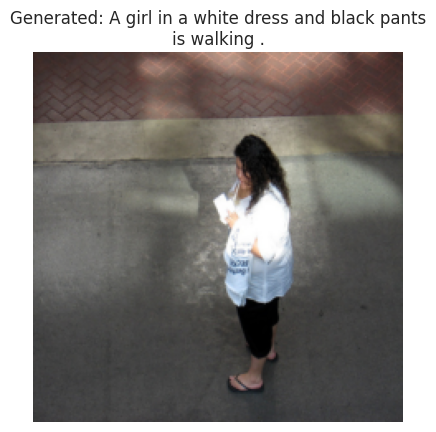

Epoch 44 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.57it/s]



Epoch 44/50 -> Train Loss: 0.7650, Val Loss: 3.6576
=> Saving checkpoint
A skateboarder does a trick on a ramp .

--- Example Prediction (Transformer Model) ---


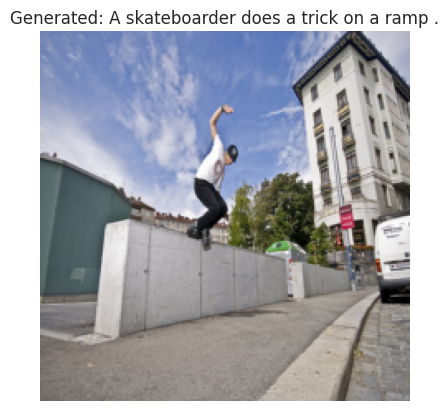

Epoch 45 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.42it/s]



Epoch 45/50 -> Train Loss: 0.7450, Val Loss: 3.6825
=> Saving checkpoint
A man in a blue shirt and jeans is watching a female tennis match .

--- Example Prediction (Transformer Model) ---


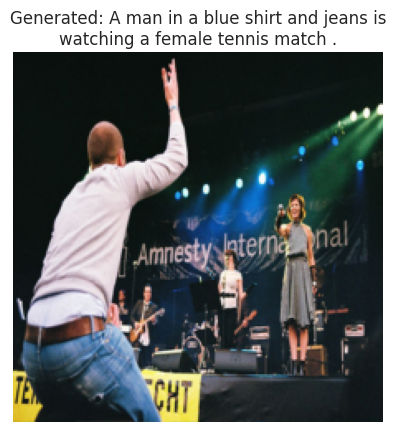

Epoch 46 [Val]: 100%|██████████| 40/40 [00:01<00:00, 35.11it/s]



Epoch 46/50 -> Train Loss: 0.7234, Val Loss: 3.7274
=> Saving checkpoint
A girl with brown hair and a black shirt is standing next to a person with a crowd of people .

--- Example Prediction (Transformer Model) ---


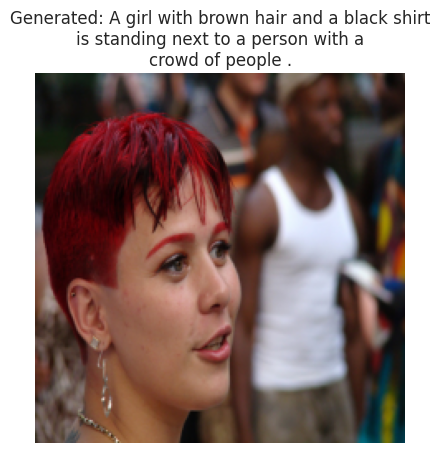

Epoch 47 [Val]: 100%|██████████| 40/40 [00:01<00:00, 34.58it/s]



Epoch 47/50 -> Train Loss: 0.7038, Val Loss: 3.7729
=> Saving checkpoint
A boy on a bike jumping over a sign .

--- Example Prediction (Transformer Model) ---


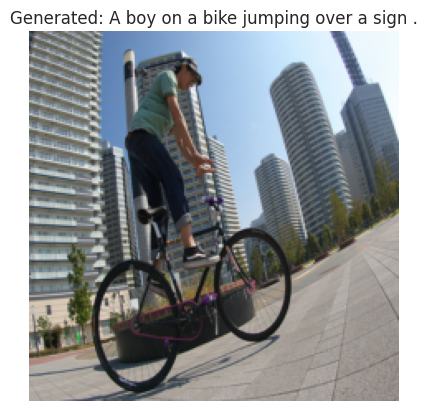

Epoch 48 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.90it/s]



Epoch 48/50 -> Train Loss: 0.6849, Val Loss: 3.7842
=> Saving checkpoint
A man on a dirt bike is midair while another man in a white shirt and black helmet is jumping his bike .

--- Example Prediction (Transformer Model) ---


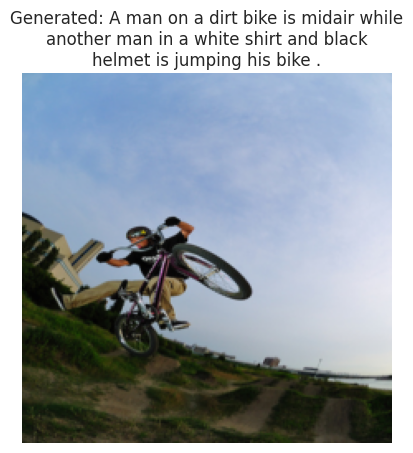

Epoch 49 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.01it/s]



Epoch 49/50 -> Train Loss: 0.6655, Val Loss: 3.8343
=> Saving checkpoint
A group of young people stand and wait for a picture .

--- Example Prediction (Transformer Model) ---


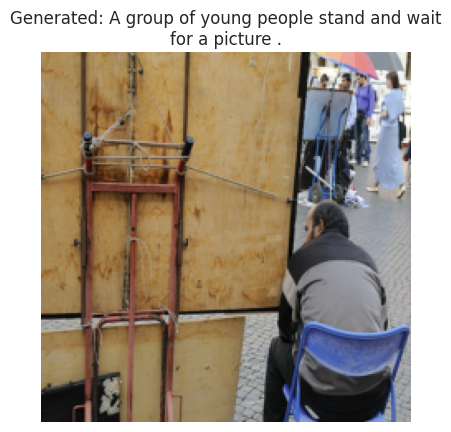

Epoch 50 [Val]: 100%|██████████| 40/40 [00:01<00:00, 33.63it/s]



Epoch 50/50 -> Train Loss: 0.6511, Val Loss: 3.8527
=> Saving checkpoint
A woman walking across a rocky beach .

--- Example Prediction (Transformer Model) ---


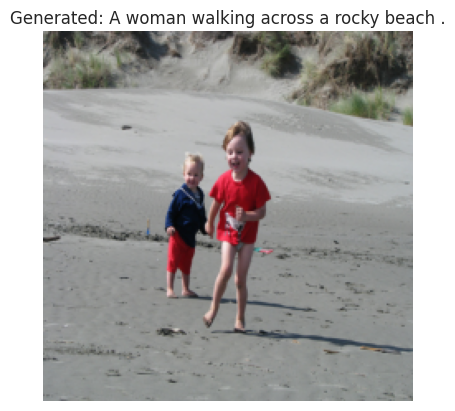

In [94]:
num_epochs_att = 50
# Call the same training function, but pass the NEW model and data loaders
train_losses_att, val_losses_att = train_transformer_model(
    model=model_tf,
    train_loader=train_loader_precomp,
    val_loader=val_loader_precomp,
    optimizer=optimizer,
    criterion=criterion,
    device=device,
    num_epochs=num_epochs_att,
    image_val_dataset=val_dataset
)

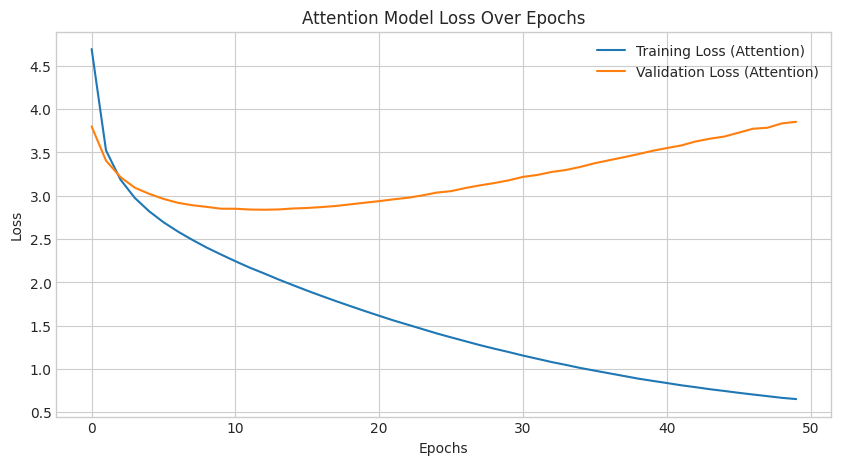


--- Final Results on Test Set (with Attention Heatmaps) ---
A tan dog chases a white dog across the grass .

--- Example Prediction (Transformer Model) ---


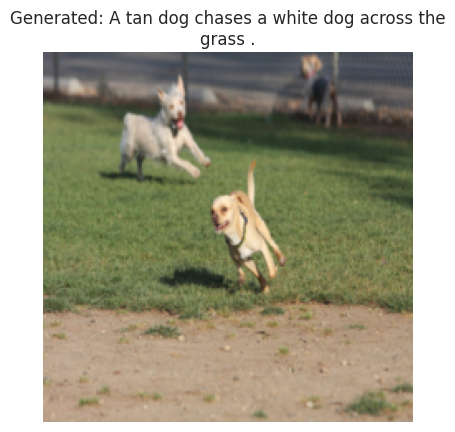

'A tan dog chases a white dog across the grass .'

In [108]:
# --- Plot Loss Curves ---
plt.figure(figsize=(10, 5))
plt.plot(train_losses_att, label='Training Loss (Attention)')
plt.plot(val_losses_att, label='Validation Loss (Attention)')
plt.title('Attention Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# --- Show 5 Final Examples ---
print("\n--- Final Results on Test Set (with Attention Heatmaps) ---")
# (You might need to recreate the test_loader with the collate_fn)
show_example_prediction_transformer(model=model_tf, feature_dataset=val_loader_precomp.dataset, image_dataset=val_dataset, device=device)

**As you can see there's sign of overfitting in the plot We ran the code for 50 epochs as wanted in question but we can prevent this by simply early stopping methods**

20
A football player in a red and white uniform is in the middle of a game .

--- Example Prediction (Transformer Model) ---


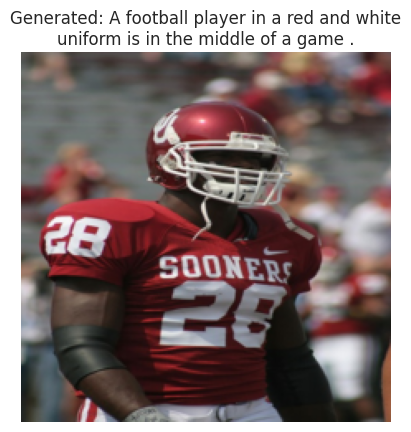

45
A basketball player in a white uniform is dribbling the ball during a game .

--- Example Prediction (Transformer Model) ---


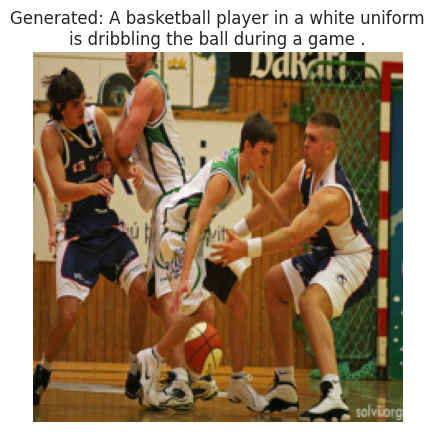

70
A man in a hat and backpack sitting on a rock overlooking a lake .

--- Example Prediction (Transformer Model) ---


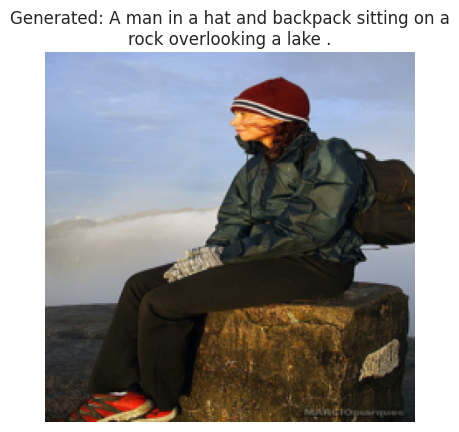

80
A small black and brown dog is playing with a toy on a grassy field .

--- Example Prediction (Transformer Model) ---


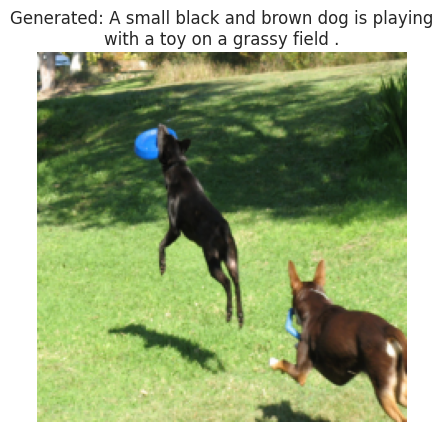

115
A boy in a red shirt is skateboarding .

--- Example Prediction (Transformer Model) ---


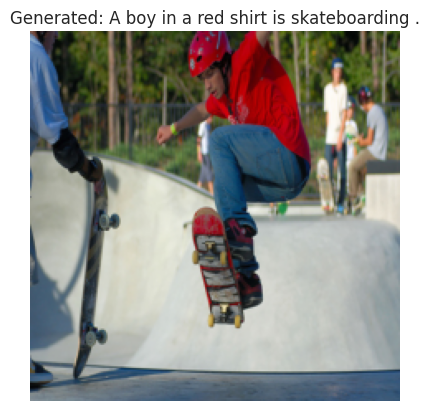

220
A man in a white shirt is standing in front of some trees .

--- Example Prediction (Transformer Model) ---


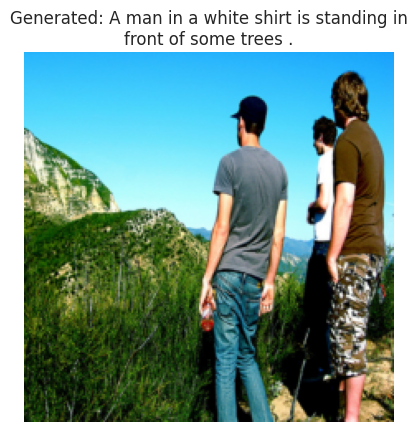

In [129]:
ids = [20, 45, 70 , 80 , 115,220]
results = {}
for i in ids:
    print(i)
    g = show_example_prediction_by_id(model=model_tf, feature_dataset=test_loader_precomp.dataset, image_dataset=test_dataset, device=device , idx=i)
    results[i] = g

In [127]:
results

{20: 'A football player in a red and white uniform is in the middle of a game .',
 25: 'A light brown dog is running through the grass .',
 45: 'A basketball player in a white uniform is dribbling the ball during a game .',
 70: 'A man in a hat and backpack sitting on a rock overlooking a lake .',
 80: 'A small black and brown dog is playing with a toy on a grassy field .',
 90: 'A brown dog is chasing after a black and white dog in a grassy field .'}

In [130]:
import json
with open ("transformer_results.json" , "w") as f:
    json.dump(results , f)

**The detailed analysis is at the end of the base notebook**